# ✈️ Malaga Airport Analytics

**Flight Routes Analysis: September 2026**

Exploratory data analysis of flight routes, origins, and destinations at Málaga-Costa del Sol Airport using Python, Pandas, and Matplotlib.

### Project Objectives

- Identify the most frequent flight destinations from Málaga.
- Discover the main airports of origin for flights arriving in Málaga.
- Analyze flight connections between Málaga and other airports.
- Visualize flight activity using real aviation data.

### Datasets

- **Flight List:** OpenSky flight records for September 2026.
- **Airport Codes:** Airport names, countries, and ICAO identifiers.

**Tools:** Python, Pandas, Matplotlib, Jupyter Notebook

## 1. Data Loading

We begin by loading the datasets using Pandas.

The flight dataset contains individual flight records, while the airport dataset provides information about airport locations, names, and country codes.

In [38]:
# ==========================================
# 1. LOAD DATASETS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df_airport_codes = pd.read_csv("data/airport-codes.csv")
df_flight_list_0926 = pd.read_parquet("data/flight_list_202609.parquet")

print("===== AIRPORTS =====")
display(df_airport_codes.head(5))
print("===== FLIGHTS =====")
display(df_flight_list_0926.head(5))

===== AIRPORTS =====


,ident,type,name,elevation_ft,continent,iso_country,iso_region,municipality,icao_code,iata_code,gps_code,local_code,coordinates
0,00A,heliport,Total RF Heliport,11.0,NaN,US,US-PA,Bensalem,NaN,NaN,K00A,00A,"40.070985, -74.933689"
1,00AA,small_airport,Aero B Ranch Airport,3435.0,NaN,US,US-KS,Leoti,NaN,NaN,00AA,00AA,"38.704022, -101.473911"
2,00AK,small_airport,Lowell Field,450.0,NaN,US,US-AK,Anchor Point,NaN,NaN,00AK,00AK,"59.947733, -151.692524"
3,00AL,small_airport,Epps Airpark,820.0,NaN,US,US-AL,Harvest,NaN,NaN,00AL,00AL,"34.86479949951172, -86.77030181884766"
4,00AN,small_airport,Katmai Lodge Airport,80.0,NaN,US,US-AK,King Salmon,NaN,NaN,00AN,00AN,"59.093287, -156.456699"


===== FLIGHTS =====


,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
0,215022979630258826,e80445,TAM8065,2026-09-01 00:00:00,NaN,NaN,NaN,NaN,CC-BGD,787 9,B789,L2J,LAN,2026-09-01 00:00:00,2026-09-01 00:30:25,v0.0.2
1,-34192608406860170,3c5426,BCS6TP,2026-09-01 00:00:00,NaN,EDDP,,,D-AEAF,A300 B4-622RF,A306,L2J,BCS,2026-09-01 00:00:00,2026-09-01 00:12:20,v0.0.2
2,1038275796220227186,407faf,TOM77V,2026-09-01 00:00:00,NaN,EGPF,,,G-TUMY,Boeing 737 MAX 8,B38M,NaN,TUI,2026-09-01 00:00:00,2026-09-01 00:14:35,v0.0.2
3,-8867045452738597801,407fc1,WUK962,2026-09-01 00:00:00,NaN,EGGW,,,G-WUKW,Airbus A321-271NX,A21N,NaN,WZZ,2026-09-01 00:00:00,2026-09-01 00:49:35,v0.0.2
4,-3919778090438063279,486a30,LIFELN4,2026-09-01 00:00:00,NaN,EHLE,,,NaN,NaN,NaN,NaN,NaN,2026-09-01 00:00:00,2026-09-01 00:14:15,v0.0.2


## 2. Dataset Overview

Before analyzing flight routes, we explore the structure of both datasets.

We examine the number of rows and columns, available variables, and data types to understand the information we are working with.

In [22]:
# ==========================================
# 2. DATASET OVERVIEW
# ==========================================

print("===== FLIGHTS =====")
print("Shape:", df_flight_list_0926.shape)
print()
display(df_flight_list_0926.info())

print("\n===== AIRPORTS =====")
print("Shape:", df_airport_codes.shape)
print()
display(df_airport_codes.info())

===== FLIGHTS =====
Shape: (1639154, 16)

<class 'pandas.DataFrame'>
RangeIndex: 1639154 entries, 0 to 1639153
Data columns (total 16 columns):
 #   Column               Non-Null Count    Dtype
---  ------               --------------    -----
 0   id                   1639154 non-null  int64
 1   icao24               1639154 non-null  str  
 2   flt_id               1505305 non-null  str  
 3   dof                  1639154 non-null  str  
 4   adep                 905082 non-null   str  
 5   ades                 956636 non-null   str  
 6   adep_p               1258896 non-null  str  
 7   ades_p               1258896 non-null  str  
 8   registration         1279064 non-null  str  
 9   model                899953 non-null   str  
 10  typecode             1274002 non-null  str  
 11  icao_aircraft_class  1079016 non-null  str  
 12  icao_operator        726091 non-null   str  
 13  first_seen           1639154 non-null  str  
 14  last_seen            1639154 non-null  str  
 15  v

None


===== AIRPORTS =====
Shape: (86258, 13)

<class 'pandas.DataFrame'>
RangeIndex: 86258 entries, 0 to 86257
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ident         86258 non-null  str    
 1   type          86258 non-null  str    
 2   name          86258 non-null  str    
 3   elevation_ft  71290 non-null  float64
 4   continent     46433 non-null  str    
 5   iso_country   85955 non-null  str    
 6   iso_region    86258 non-null  str    
 7   municipality  81490 non-null  str    
 8   icao_code     10554 non-null  str    
 9   iata_code     9051 non-null   str    
 10  gps_code      44491 non-null  str    
 11  local_code    36132 non-null  str    
 12  coordinates   86258 non-null  str    
dtypes: float64(1), str(12)
memory usage: 15.5 MB


None

## 3. Data Quality

We check for missing values and duplicated records in both datasets.

This helps us identify potential data quality issues before performing the analysis.

At this stage, we only inspect the data without making modifications.

In [ ]:
# ==========================================
# MISSING VALUES
# ==========================================

print("===== FLIGHTS =====")
display(df_flight_list_0926.isna().sum())

print("===== AIRPORTS =====")
display(df_airport_codes.isna().sum())

===== FLIGHTS =====


id                          0
icao24                      0
flt_id                 133849
dof                         0
adep                   734072
ades                   682518
adep_p                 380258
ades_p                 380258
registration           360090
model                  739201
typecode               365152
icao_aircraft_class    560138
icao_operator          913063
first_seen                  0
last_seen                   0
version                     0
dtype: int64

===== AIRPORTS =====


ident               0
type                0
name                0
elevation_ft    14968
continent       39825
iso_country       303
iso_region          0
municipality     4768
icao_code       75704
iata_code       77207
gps_code        41767
local_code      50126
coordinates         0
dtype: int64

In [ ]:
# ==========================================
# DUPLICATES
# ==========================================

print("===== DUPLICATES =====")

print("Flights:", df_flight_list_0926.duplicated().sum())
print("Airports:", df_airport_codes.duplicated().sum())

===== DUPLICATES =====
Flights: 1088
Airports: 0


## 4. Malaga Airport Flights

We focus on flights departing from or arriving at Málaga-Costa del Sol Airport.

The ICAO airport code for Málaga is **LEMG**.

We create two DataFrames:

- **Departures:** Flights departing from Málaga.
- **Arrivals:** Flights arriving at Málaga.

This initial analysis uses the `adep` and `ades` columns. Alternative airport fields will be reviewed before drawing final conclusions.

In [ ]:
# ==========================================
# 4. MALAGA FLIGHTS
# ==========================================

# Flights departing from Malaga
df_departures_malaga = df_flight_list_0926[
    df_flight_list_0926["adep"] == "LEMG"
].copy()

# Flights arriving at Malaga
df_arrivals_malaga = df_flight_list_0926[
    df_flight_list_0926["ades"] == "LEMG"
].copy()

print("Departures:", len(df_departures_malaga))
print("Arrivals:", len(df_arrivals_malaga))
print("Total Flights SEP26:", len(df_departures_malaga) + len(df_arrivals_malaga))

Departures: 9631
Arrivals: 9764
Total Flights SEP26: 19395


## 5. Top 10 Flight Destinations

    Which airports receive the most flights departing from Málaga?

We use `value_counts()` to identify the ten most frequent destinations and visualize the results with Matplotlib.

In [ ]:
# ==========================================
# 5. TOP 10 DESTINATIONS
# ==========================================

top_destinations = df_departures_malaga["ades"].value_counts().head(10)

display(top_destinations)

ades
EGKK    350
EHAM    279
LEBL    267
LEMD    251
EIDW    223
EBBR    202
EGCC    182
EKCH    181
LFPO    165
GEML    150
Name: count, dtype: int64

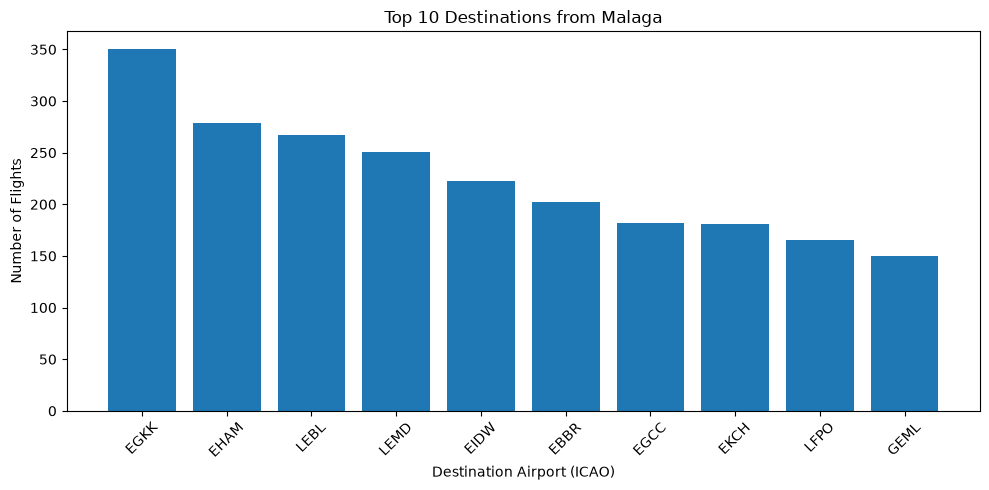

In [34]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_destinations.index,
    top_destinations.values
)

plt.title("Top 10 Destinations from Malaga")
plt.xlabel("Destination Airport (ICAO)")
plt.ylabel("Number of Flights")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6. Top 10 Flight Origins

    Where do flights arriving in Málaga come from?

We analyze the most frequent departure airports for flights arriving at Málaga and display the results using a bar chart.

In [ ]:
# ==========================================
# 6. TOP 10 ORIGINS
# ==========================================

top_origins = df_arrivals_malaga["adep"].value_counts().head(10)

display(top_origins)

adep
EGKK    352
EHAM    281
LEMD    266
LEBL    262
EIDW    230
EBBR    204
EGCC    181
EKCH    179
LFPO    169
LIRF    144
Name: count, dtype: int64

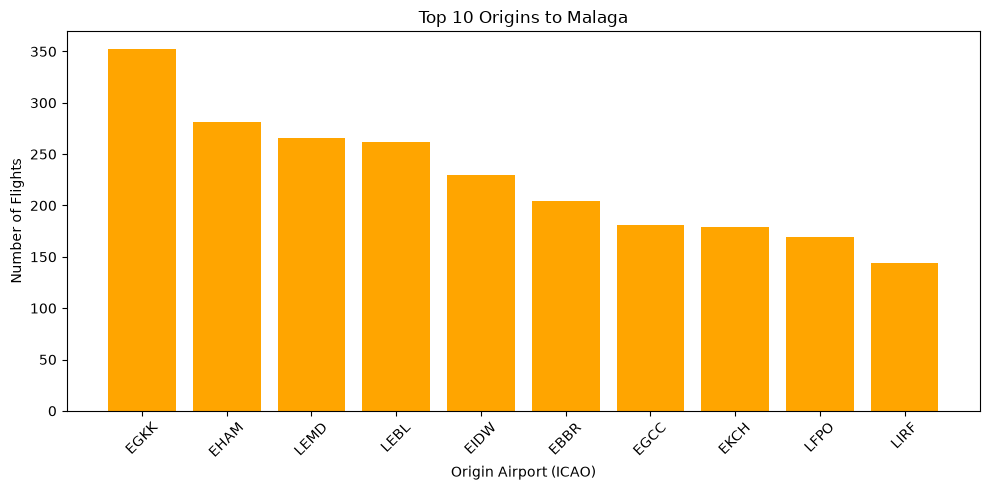

In [39]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_origins.index,
    top_origins.values,
    color="orange"
)

plt.title("Top 10 Origins to Malaga")
plt.xlabel("Origin Airport (ICAO)")
plt.ylabel("Number of Flights")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()